<a href="https://colab.research.google.com/github/mvishrutha/BIS-LAB-/blob/main/Week-2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import cv2
import random

# 1. Create a dummy grayscale image (a dark background with a bright square)
# This gives the algorithm something obvious to segment!
image = np.zeros((300, 300), dtype=np.uint8)
cv2.rectangle(image, (50, 50), (250, 250), 180, -1)  # Draw a bright square

# 2. Compute the image histogram for Otsu's Variance calculations
hist = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()
total_pixels = image.size

def calculate_otsu_variance(threshold):
    """Calculates how well a threshold splits the image into dark and light."""
    t = int(clip(threshold, 0, 255))

    # Weight and mean for background (pixels below threshold)
    w0 = np.sum(hist[:t]) / total_pixels
    if w0 == 0: return 0
    m0 = np.sum(np.arange(t) * hist[:t]) / (w0 * total_pixels)

    # Weight and mean for foreground (pixels above threshold)
    w1 = np.sum(hist[t:]) / total_pixels
    if w1 == 0: return 0
    m1 = np.sum(np.arange(t, 256) * hist[t:]) / (w1 * total_pixels)

    # Otsu's between-class variance formula
    variance = w0 * w1 * (m0 - m1) ** 2
    return variance

def clip(val, min_val, max_val):
    """Helper function to keep numbers within bounds."""
    return max(min_val, min(val, max_val))

# --- PSO ALGORITHM START ---

# Hyperparameters
num_particles = 20
max_iterations = 50
w, c1, c2 = 0.5, 1.5, 1.5  # Standard PSO control weights

# Setup arrays to track particle states (Lines 1-7 in pseudocode)
thresholds = np.random.uniform(0, 255, num_particles)
speeds = np.random.uniform(-5, 5, num_particles)

my_best_thresholds = np.copy(thresholds)
my_best_variances = np.array([-1.0] * num_particles)

group_best_threshold = 0.0
group_best_variance = -1.0

# The Main Hunt Loop (Line 8)
for iteration in range(max_iterations):
    for i in range(num_particles):
        # Calculate score (Line 10)
        variance = calculate_otsu_variance(thresholds[i])

        # Update Personal Best (Lines 11-13)
        if variance > my_best_variances[i]:
            my_best_variances[i] = variance
            my_best_thresholds[i] = thresholds[i]

        # Update Group Best (Lines 14-16)
        if variance > group_best_variance:
            group_best_variance = variance
            group_best_threshold = thresholds[i]

    # Move the particles (Lines 17-20)
    for i in range(num_particles):
        r1, r2 = random.random(), random.random()

        # Update speed formula
        speeds[i] = (w * speeds[i]) + \
                    (c1 * r1 * (my_best_thresholds[i] - thresholds[i])) + \
                    (c2 * r2 * (group_best_threshold - thresholds[i]))

        # Update physical threshold value
        thresholds[i] = thresholds[i] + speeds[i]
        thresholds[i] = clip(thresholds[i], 0, 255)

# --- RESULTS ---
final_threshold = int(round(group_best_threshold))
print(f"​​🎉 Optimization Complete!")
print(f"Optimal Segmenting Threshold Found by PSO: {final_threshold}")

# Apply the threshold to binary segment the image (Black and White)
_, segmented_image = cv2.threshold(image, final_threshold, 255, cv2.THRESH_BINARY)
print("Image successfully segmented into distinct regions!")

​​🎉 Optimization Complete!
Optimal Segmenting Threshold Found by PSO: 64
Image successfully segmented into distinct regions!


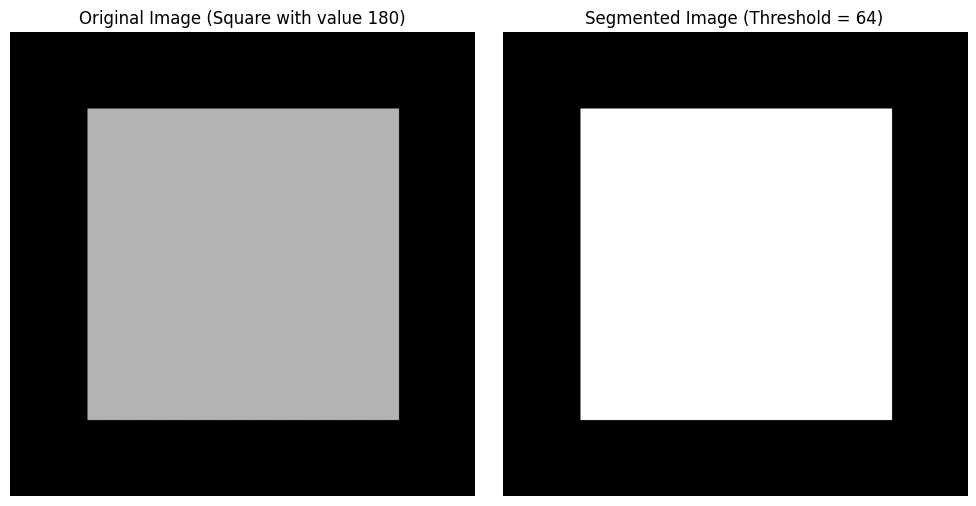

In [3]:
import matplotlib.pyplot as plt

# Create a side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Plot original image
axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original Image (Square with value 180)")
axes[0].axis('off')

# Plot segmented image using threshold 64
axes[1].imshow(segmented_image, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"Segmented Image (Threshold = {final_threshold})")
axes[1].axis('off')

plt.tight_layout()
plt.show()